In [1]:
!pip install rasterio

In [2]:

import rasterio

# Replace these filenames if yours differ
green_path = "/content/2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B03_(Raw)(1).tif"
nir_path = "/content/2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B08_(Raw)(1).tif"

# Open both satellite bands
green = rasterio.open(green_path)
nir = rasterio.open(nir_path)

# Inspect their properties
print("GREEN BAND (B03)")
print("Dimensions:", green.width, "x", green.height)
print("CRS:", green.crs)
print("Resolution:", green.res)

print("\nNIR BAND (B08)")
print("Dimensions:", nir.width, "x", nir.height)
print("CRS:", nir.crs)
print("Resolution:", nir.res)


RasterioIOError: /content/2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B03_(Raw)(1).tif: No such file or directory

In [3]:

import os

print(os.listdir("/content"))


['.config', '2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B03_(Raw)(1).tiff', '2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B08_(Raw)(1).tiff', 'sample_data']


In [4]:

import rasterio

green_path = "/content/2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B03_(Raw)(1).tiff"
nir_path = "/content/2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B08_(Raw)(1).tiff"

green = rasterio.open(green_path)
nir = rasterio.open(nir_path)

print("GREEN BAND (B03)")
print("Dimensions:", green.width, "x", green.height)
print("CRS:", green.crs)
print("Resolution:", green.res)

print("\nNIR BAND (B08)")
print("Dimensions:", nir.width, "x", nir.height)
print("CRS:", nir.crs)
print("Resolution:", nir.res)


GREEN BAND (B03)
Dimensions: 212 x 174
CRS: EPSG:4326
Resolution: (9.008962264150828e-05, 8.974712643677948e-05)

NIR BAND (B08)
Dimensions: 212 x 174
CRS: EPSG:4326
Resolution: (9.008962264150828e-05, 8.974712643677948e-05)


In [5]:

import numpy as np

# Read the satellite band data
green_data = green.read(1).astype("float32")
nir_data = nir.read(1).astype("float32")

# Calculate NDWI
denominator = green_data + nir_data

ndwi = np.divide(
    green_data - nir_data,
    denominator,
    out=np.zeros_like(green_data),
    where=denominator != 0
)

print("NDWI calculation completed!")
print("Minimum NDWI:", np.nanmin(ndwi))
print("Maximum NDWI:", np.nanmax(ndwi))
print("Mean NDWI:", np.nanmean(ndwi))


NDWI calculation completed!
Minimum NDWI: -0.66897833
Maximum NDWI: 0.3607306
Mean NDWI: 0.0072394526


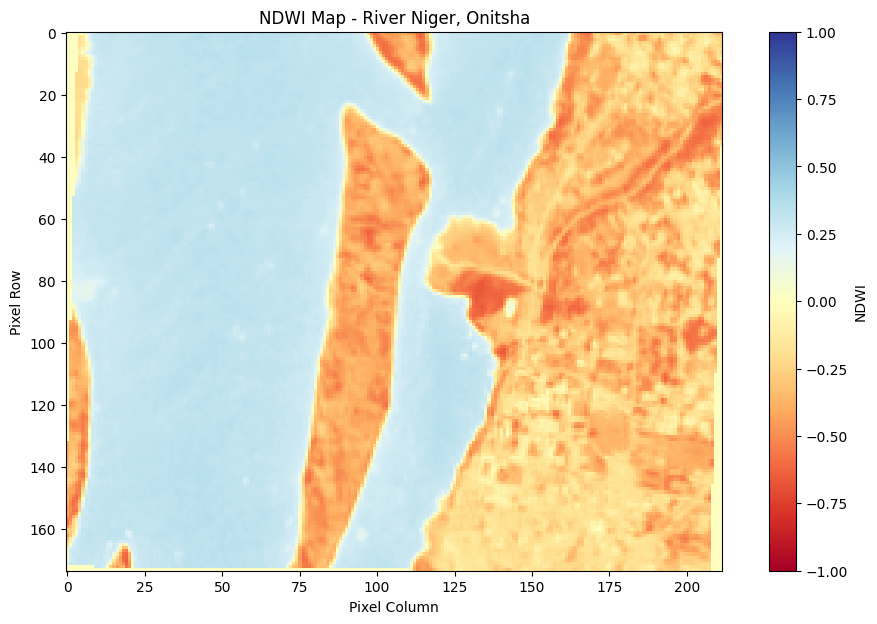

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.imshow(
    ndwi,
    cmap="RdYlBu",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="NDWI")
plt.title("NDWI Map - River Niger, Onitsha")
plt.xlabel("Pixel Column")
plt.ylabel("Pixel Row")

plt.show()


In [1]:

!pip install scikit-image


In [2]:

import matplotlib.pyplot as plt
import numpy as np
from skimage.filters import threshold_otsu

# Calculate an initial data-driven threshold
threshold = threshold_otsu(ndwi)

print("Otsu threshold:", threshold)

# Plot the NDWI value distribution
plt.figure(figsize=(10, 5))

plt.hist(ndwi.ravel(), bins=100)
plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label=f"Otsu threshold = {threshold:.4f}"
)

plt.title("NDWI Value Distribution")
plt.xlabel("NDWI")
plt.ylabel("Number of Pixels")
plt.legend()
plt.show()


NameError: name 'ndwi' is not defined

In [3]:

import rasterio
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu

# 1. Load the satellite bands
green_path = "/content/2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B03_(Raw)(1).tiff"
nir_path = "/content/2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B08_(Raw)(1).tiff"

with rasterio.open(green_path) as green:
    green_data = green.read(1).astype("float32")

with rasterio.open(nir_path) as nir:
    nir_data = nir.read(1).astype("float32")

# 2. Calculate NDWI
denominator = green_data + nir_data

ndwi = np.divide(
    green_data - nir_data,
    denominator,
    out=np.zeros_like(green_data),
    where=denominator != 0
)

# 3. Calculate Otsu threshold
threshold = threshold_otsu(ndwi)

print("NDWI calculation completed.")
print("Otsu threshold:", threshold)

# 4. Plot NDWI distribution
plt.figure(figsize=(10, 5))

plt.hist(ndwi.ravel(), bins=100)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label=f"Threshold = {threshold:.4f}"
)

plt.title("NDWI Value Distribution")
plt.xlabel("NDWI")
plt.ylabel("Number of Pixels")
plt.legend()
plt.show()


RasterioIOError: /content/2026-02-05-00_00_2026-02-05-23_59_Sentinel-2_L2A_B03_(Raw)(1).tiff: No such file or directory

NDWI calculation completed.
Otsu threshold: -0.019376844


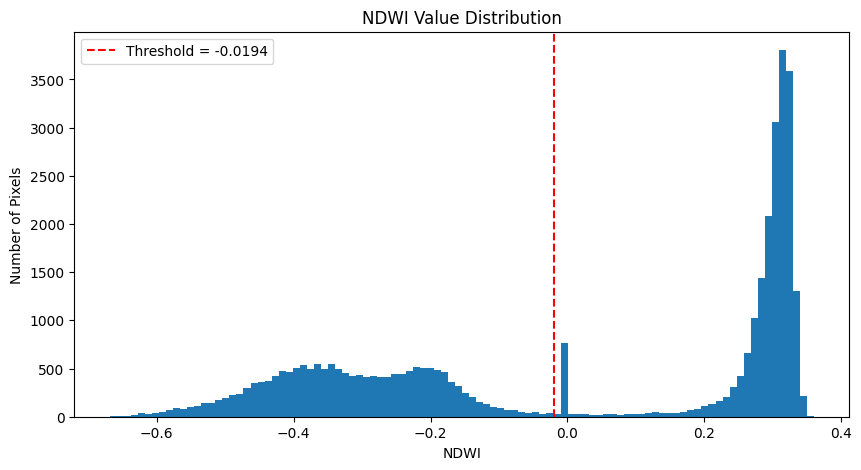

In [4]:
import glob
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu

# Locate the uploaded files
green_files = glob.glob("/content/*B03*Raw*.tiff")
nir_files = glob.glob("/content/*B08*Raw*.tiff")

if not green_files or not nir_files:
    raise FileNotFoundError("Please upload both B03 and B08 TIFF files.")

# Read the bands
with rasterio.open(green_files[0]) as src:
    green_data = src.read(1).astype("float32")

with rasterio.open(nir_files[0]) as src:
    nir_data = src.read(1).astype("float32")

# Calculate NDWI
denominator = green_data + nir_data

ndwi = np.divide(
    green_data - nir_data,
    denominator,
    out=np.zeros_like(green_data),
    where=denominator != 0
)

# Calculate Otsu threshold
threshold = threshold_otsu(ndwi)

print("NDWI calculation completed.")
print("Otsu threshold:", threshold)

# Plot histogram
plt.figure(figsize=(10, 5))
plt.hist(ndwi.ravel(), bins=100)
plt.axvline(threshold, color="red", linestyle="--",
            label=f"Threshold = {threshold:.4f}")
plt.title("NDWI Value Distribution")
plt.xlabel("NDWI")
plt.ylabel("Number of Pixels")
plt.legend()
plt.show()

Valid pixels: 36145
Otsu threshold: -0.015354544


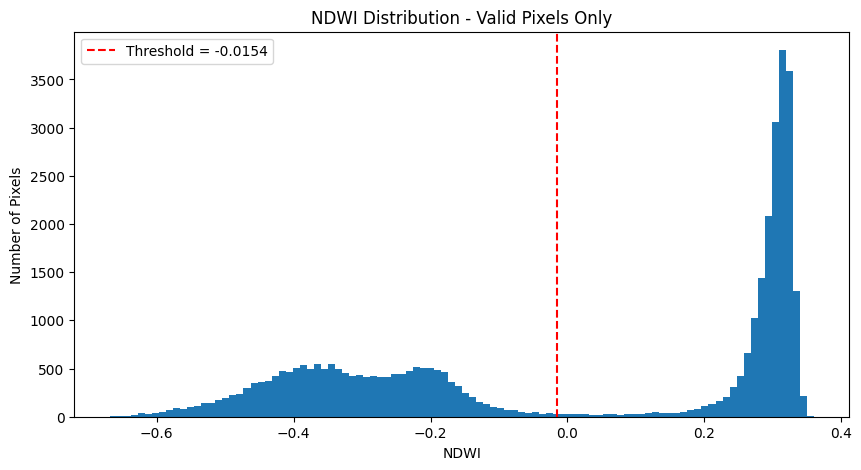

In [5]:

# Identify pixels with valid NDWI calculations
valid_mask = (
    (green_data + nir_data != 0) &
    np.isfinite(ndwi)
)

# Extract only valid NDWI values
valid_ndwi = ndwi[valid_mask]

# Recalculate Otsu threshold
threshold = threshold_otsu(valid_ndwi)

print("Valid pixels:", valid_ndwi.size)
print("Otsu threshold:", threshold)

# Plot corrected histogram
plt.figure(figsize=(10, 5))

plt.hist(valid_ndwi, bins=100)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label=f"Threshold = {threshold:.4f}"
)

plt.title("NDWI Distribution - Valid Pixels Only")
plt.xlabel("NDWI")
plt.ylabel("Number of Pixels")
plt.legend()
plt.show()


Candidate water pixels: 19240
Valid pixels: 36145
Candidate water coverage: 53.23 %


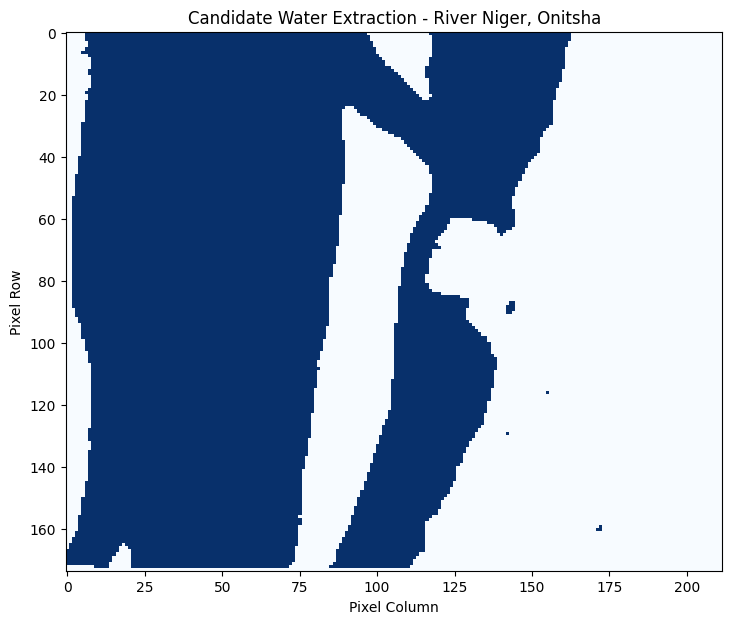

In [6]:

# Create binary water mask
water_mask = (ndwi > threshold) & valid_mask

# Calculate candidate water coverage
water_pixels = np.sum(water_mask)
valid_pixels = np.sum(valid_mask)

water_percentage = (water_pixels / valid_pixels) * 100

print("Candidate water pixels:", water_pixels)
print("Valid pixels:", valid_pixels)
print("Candidate water coverage:", round(water_percentage, 2), "%")

# Visualise the water mask
plt.figure(figsize=(12, 7))

plt.imshow(water_mask, cmap="Blues")
plt.title("Candidate Water Extraction - River Niger, Onitsha")
plt.xlabel("Pixel Column")
plt.ylabel("Pixel Row")

plt.show()


OBIA segmentation completed!
Number of objects: 168


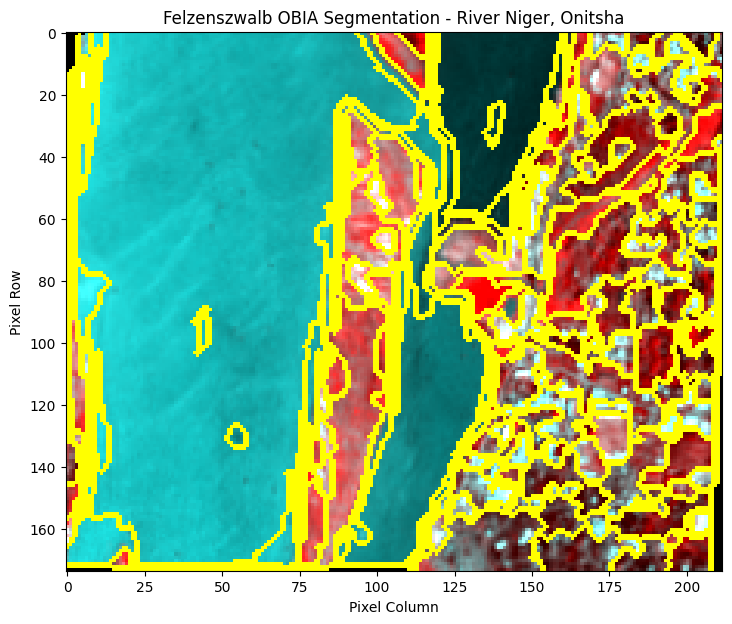

In [7]:

from skimage.segmentation import felzenszwalb, mark_boundaries
import numpy as np
import matplotlib.pyplot as plt

# 1. Normalise the Green and NIR bands
def percentile_stretch(image, mask):
    low, high = np.percentile(image[mask], [2, 98])
    return np.clip((image - low) / (high - low), 0, 1)

green_norm = percentile_stretch(green_data, valid_mask)
nir_norm = percentile_stretch(nir_data, valid_mask)

# 2. Normalise NDWI to the range 0–1
ndwi_norm = np.clip((ndwi + 1) / 2, 0, 1)

# 3. Create a three-layer feature image
feature_image = np.dstack([
    green_norm,
    nir_norm,
    ndwi_norm
])

# 4. Apply Felzenszwalb segmentation
segments = felzenszwalb(
    feature_image,
    scale=100,
    sigma=0.8,
    min_size=30,
    channel_axis=-1
)

# 5. Count the resulting geographic objects
number_of_segments = len(np.unique(segments))

print("OBIA segmentation completed!")
print("Number of objects:", number_of_segments)

# 6. Display segmentation boundaries
false_colour = np.dstack([
    nir_norm,
    green_norm,
    green_norm
])

plt.figure(figsize=(14, 7))

plt.imshow(mark_boundaries(false_colour, segments))
plt.title("Felzenszwalb OBIA Segmentation - River Niger, Onitsha")
plt.xlabel("Pixel Column")
plt.ylabel("Pixel Row")

plt.show()


Total segmented objects: 168
Objects classified as water: 32
Final water pixels: 19437


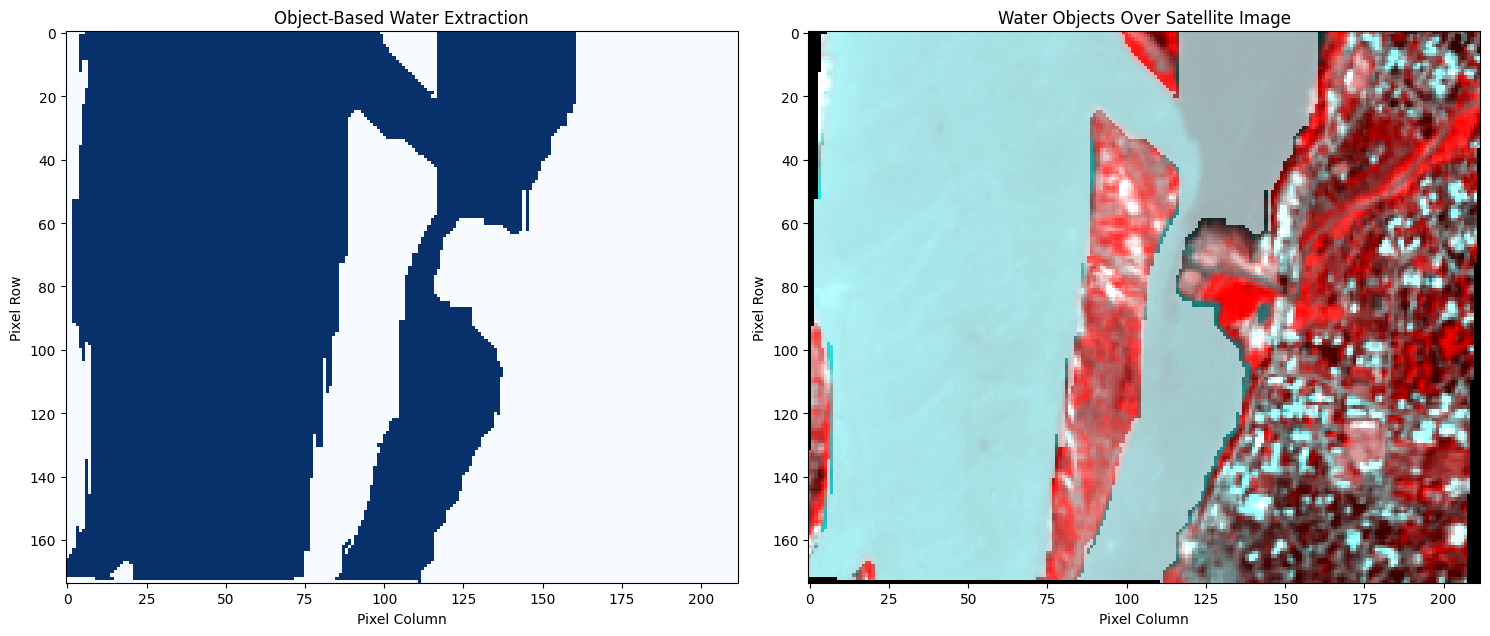

In [8]:

# Get the total number of segmented objects
segment_ids = np.unique(segments)
number_of_segments = len(segment_ids)

# Flatten the arrays for counting
flat_segments = segments.ravel()
flat_valid = valid_mask.ravel()
flat_water = water_mask.ravel()

# Count valid pixels and candidate water pixels per object
valid_counts = np.bincount(
    flat_segments,
    weights=flat_valid.astype(int)
)

water_counts = np.bincount(
    flat_segments,
    weights=flat_water.astype(int)
)

# Calculate the proportion of water pixels in each object
water_fraction = np.divide(
    water_counts,
    valid_counts,
    out=np.zeros_like(water_counts, dtype=float),
    where=valid_counts > 0
)

# Classify objects using majority voting
water_objects = (
    (valid_counts > 0) &
    (water_fraction >= 0.50)
)

# Create the final object-based water mask
final_water_mask = water_objects[segments] & valid_mask

print("Total segmented objects:", number_of_segments)
print("Objects classified as water:", np.sum(water_objects))
print("Final water pixels:", np.sum(final_water_mask))

# Visualise the result
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(final_water_mask, cmap="Blues")
axes[0].set_title("Object-Based Water Extraction")

overlay = false_colour.copy()
axes[1].imshow(overlay)
axes[1].imshow(
    np.ma.masked_where(~final_water_mask, final_water_mask),
    cmap="Blues",
    alpha=0.65
)
axes[1].set_title("Water Objects Over Satellite Image")

for ax in axes:
    ax.set_xlabel("Pixel Column")
    ax.set_ylabel("Pixel Row")

plt.tight_layout()
plt.show()


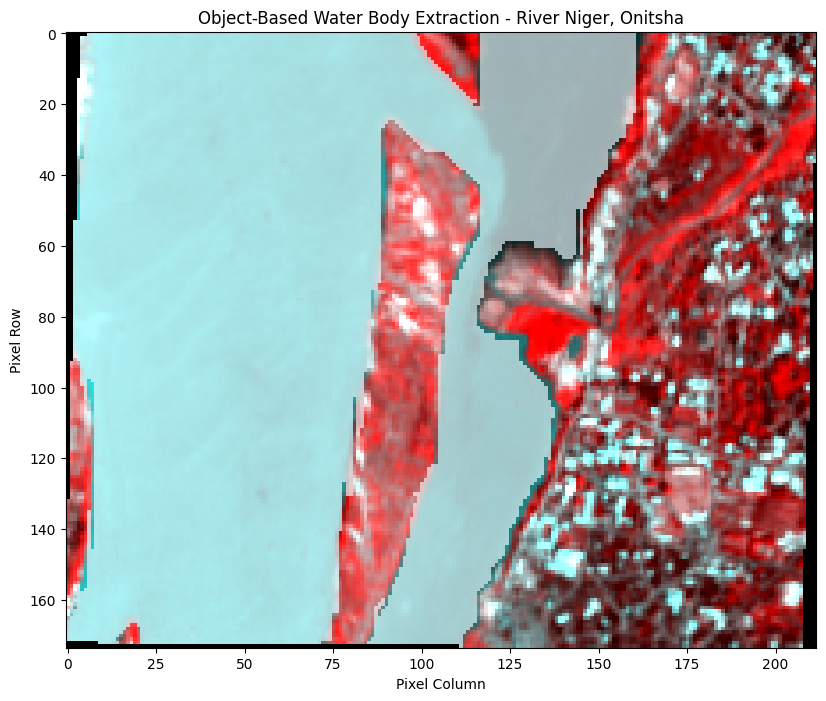

EXPORT COMPLETED
GeoTIFF: /content/river_niger_onitsha_water_mask.tif
GeoJSON: /content/river_niger_onitsha_water_bodies.geojson
PNG: /content/river_niger_onitsha_final_map.png
Water polygon features: 1
Coordinate Reference System: EPSG:4326


In [9]:

import rasterio
import json
import numpy as np
import matplotlib.pyplot as plt

from rasterio.features import shapes

# Locate the original Green band for geospatial metadata
green_file = green_files[0]

with rasterio.open(green_file) as src:
    profile = src.profile.copy()
    transform = src.transform
    crs = src.crs

# --------------------------------
# 1. EXPORT WATER MASK AS GEOTIFF
# --------------------------------

# 0 = Non-water
# 1 = Water
# 255 = Invalid pixels

output_mask = np.full(final_water_mask.shape, 255, dtype="uint8")
output_mask[valid_mask] = 0
output_mask[final_water_mask] = 1

profile.update(
    driver="GTiff",
    count=1,
    dtype="uint8",
    nodata=255,
    compress="deflate"
)

geotiff_path = "/content/river_niger_onitsha_water_mask.tif"

with rasterio.open(geotiff_path, "w", **profile) as dst:
    dst.write(output_mask, 1)

# --------------------------------
# 2. EXPORT WATER POLYGONS AS GEOJSON
# --------------------------------

features = []

for geometry, value in shapes(
    final_water_mask.astype("uint8"),
    mask=final_water_mask,
    transform=transform,
    connectivity=8
):
    if value == 1:
        features.append({
            "type": "Feature",
            "properties": {
                "class": "Water",
                "source": "Sentinel-2 NDWI and Felzenszwalb OBIA"
            },
            "geometry": geometry
        })

geojson = {
    "type": "FeatureCollection",
    "features": features
}

geojson_path = "/content/river_niger_onitsha_water_bodies.geojson"

with open(geojson_path, "w") as f:
    json.dump(geojson, f)

# --------------------------------
# 3. CREATE FINAL VISUALISATION
# --------------------------------

plt.figure(figsize=(12, 8))

plt.imshow(false_colour)
plt.imshow(
    np.ma.masked_where(
        ~final_water_mask,
        final_water_mask
    ),
    cmap="Blues",
    alpha=0.65
)

plt.title("Object-Based Water Body Extraction - River Niger, Onitsha")
plt.xlabel("Pixel Column")
plt.ylabel("Pixel Row")
plt.savefig(
    "/content/river_niger_onitsha_final_map.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("EXPORT COMPLETED")
print("GeoTIFF:", geotiff_path)
print("GeoJSON:", geojson_path)
print("PNG:", "/content/river_niger_onitsha_final_map.png")
print("Water polygon features:", len(features))
print("Coordinate Reference System:", crs)


In [10]:

import json
import numpy as np
from rasterio.features import shapes

features = []

# Export each classified water object separately
for segment_id in np.where(water_objects)[0]:

    object_mask = (segments == segment_id) & valid_mask

    if not np.any(object_mask):
        continue

    object_geometries = shapes(
        object_mask.astype("uint8"),
        mask=object_mask,
        transform=transform
    )

    for geometry, value in object_geometries:

        if value != 1:
            continue

        pixel_count = int(np.sum(object_mask))
        mean_ndwi = float(np.mean(ndwi[object_mask]))
        water_fraction_value = float(water_fraction[segment_id])

        features.append({
            "type": "Feature",
            "properties": {
                "object_id": int(segment_id),
                "class": "Water",
                "pixel_count": pixel_count,
                "mean_ndwi": mean_ndwi,
                "water_fraction": water_fraction_value
            },
            "geometry": geometry
        })

object_geojson = {
    "type": "FeatureCollection",
    "features": features
}

output_path = "/content/river_niger_onitsha_OBIA_objects.geojson"

with open(output_path, "w") as f:
    json.dump(object_geojson, f)

print("Object-level GeoJSON created.")
print("Water object features:", len(features))
print("Output:", output_path)


Object-level GeoJSON created.
Water object features: 71
Output: /content/river_niger_onitsha_OBIA_objects.geojson


In [11]:

import json
import numpy as np
from rasterio.features import shapes
from shapely.geometry import shape, mapping
from shapely.ops import unary_union

features = []

for segment_id in np.where(water_objects)[0]:

    object_mask = (segments == segment_id) & valid_mask

    if not np.any(object_mask):
        continue

    geometries = []

    for geometry, value in shapes(
        object_mask.astype("uint8"),
        mask=object_mask,
        transform=transform,
        connectivity=8
    ):
        if value == 1:
            geometries.append(shape(geometry))

    if not geometries:
        continue

    # Combine all polygon parts belonging to this object
    combined_geometry = unary_union(geometries)

    features.append({
        "type": "Feature",
        "properties": {
            "object_id": int(segment_id),
            "class": "Water",
            "pixel_count": int(np.sum(object_mask)),
            "mean_ndwi": float(np.mean(ndwi[object_mask])),
            "water_fraction": float(water_fraction[segment_id])
        },
        "geometry": mapping(combined_geometry)
    })

object_geojson = {
    "type": "FeatureCollection",
    "features": features
}

output_path = "/content/river_niger_onitsha_OBIA_objects_corrected.geojson"

with open(output_path, "w") as f:
    json.dump(object_geojson, f)

print("Corrected GeoJSON exported.")
print("Total features:", len(features))
print("Unique object IDs:", len(set(
    feature["properties"]["object_id"]
    for feature in features
)))


Corrected GeoJSON exported.
Total features: 32
Unique object IDs: 32
